# 卷积：从冲激到回声与平滑

对应笔记：`../../../卷积.md`。所有数据在本地合成，无需下载。先运行准备单元，再按顺序运行；修改各节开头参数即可重复实验。

目标：用图像和数值验证公式，并理解公式能解决什么问题。数值验证只覆盖所选案例，不代替数学证明。

**绘图约定：** 离散序列、采样测量与 DFT/FFT 频点采用竖杆图，样本之间不连线；连续时间或连续频率模型用曲线。各分量与结果分开成图，子图标题说明角色。较长序列会展示注明范围的局部，计算仍使用完整数据。

**学习方法：** 每节先读“要理解什么”与数学等式，把公式左右两边对应到代码及子图，再看计算误差或反例。重点是解释公式；实际应用用于帮助理解。数值近似、有限案例、理论恒等式和广义函数极限在各节分别说明。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, integrate
from IPython.display import display, Markdown
rng = np.random.default_rng(42)
plt.rcParams.update({'figure.figsize': (9, 3), 'axes.grid': True})
# 图中使用英文标签，避免系统缺少中文字体；讲解和结果说明使用中文。
def graph(x, curves, xlabel='Sample index n', ylabel='Amplitude', *, kind='discrete', xlim=None):
    """每个分量独占子图；离散样本不连线，连续模型用曲线。"""
    import matplotlib.ticker as ticker
    count = len(curves)
    cols = min(2, count)
    rows = (count + cols - 1) // cols
    fig = plt.figure(figsize=(12 if cols == 2 else 10, 2.8 * rows), layout='constrained')
    grid = fig.add_gridspec(rows, cols)
    x = np.asarray(x)
    axes = []
    for i, (label, values) in enumerate(curves.items()):
        # 奇数个分量时，最后的结果图占满一行。
        slot = grid[i // cols, :] if count % 2 and i == count - 1 else grid[i // cols, i % cols]
        ax = fig.add_subplot(slot)
        values = np.asarray(values)
        color = f'C{i % 10}'
        if kind == 'discrete':
            marker, stems, baseline = ax.stem(x, values, basefmt='k-')
            plt.setp(marker, color=color, markersize=3 if len(x)>80 else 5)
            plt.setp(stems, color=color, linewidth=0.8 if len(x)>80 else 1.5)
            plt.setp(baseline, linewidth=0.5)
            if np.allclose(x, np.round(x)):
                ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=12, integer=True))
            if len(x) <= 20:
                ax.set_xticks(x)
                for xi, yi in zip(x, values):
                    if abs(yi) > max(1e-12, 0.05 * np.max(np.abs(values))):
                        ax.annotate(f'{yi:.3g}', (xi, yi), xytext=(0, 6 if yi >= 0 else -12),
                                    textcoords='offset points', ha='center', fontsize=8)
            ax.margins(y=0.2)
        elif kind == 'continuous':
            ax.plot(x, values, color=color, linewidth=1.5)
        else:
            raise ValueError('kind must be discrete or continuous')
        ax.set(title=label, xlabel=xlabel, ylabel=ylabel)
        if xlim is not None:
            ax.set_xlim(xlim)
        ax.grid(True, alpha=0.25)
        ax.set_axisbelow(True)
        axes.append(ax)
    plt.show()
    return axes

def err(a, b):
    return float(np.max(np.abs(np.asarray(a)-np.asarray(b))))


## 实验 1：冲激、阶跃与冲激分解（离散竖杆图）

**要理解什么：** 理解一个信号为什么能拆成许多冲激；区分阶跃、冲激和重建信号。

**要验证的数学形式（对照[原笔记](../../../卷积.md)）：**

$$
\begin{gathered}
\delta[n]=\begin{cases}1,&n=0\\0,&n\ne0\end{cases},\quad \delta[n]=u[n]-u[n-1] \\[6pt]
\boxed{x[n]=\sum_{k=-\infty}^{+\infty}x[k]\delta[n-k]}
\end{gathered}
$$

**符号与代码怎样对应：** `n` 是正在查看的整数位置，`k` 是分量发生的位置；`x=[2,3,1]` 表示 x[0]、x[1]、x[2]。`parts[k]` 就是一整条加权冲激分量，`parts.sum(axis=0)` 是逐位置相加。

**怎样读图、怎样判断结果：** 第二行三幅图对应 $2\delta[n]$、$3\delta[n-1]$、$\delta[n-2]$。最后一幅应只在 0、1、2 处出现 2、3、1；例如 $x[1]=0+3+0=3$。前两幅基础信号不参与这次求和。

**先预测，再改参数：** 把 x[1] 从 3 改为 5：应只改变第二个冲激和重建结果在 n=1 的高度。

**本例设置与适用范围：**

覆盖笔记一至三。横轴 $n$ 只取整数；每个圆点表示一个样本，竖杆表示该样本的幅值，**相邻样本之间不连线**。

先看第一行：左图是单位阶跃 $u[n]$，右图是单位冲激 $\delta[n]$。第二行分别展示三个加权、平移后的冲激；最后一行是它们相加得到的信号：

$$x[n]=2\delta[n]+3\delta[n-1]+\delta[n-2].$$

注意：阶跃与单位冲激是基础信号示例，**不是把第一行两幅图相加得到重建信号**。另有 $\delta[n]=u[n]-u[n-1]$。

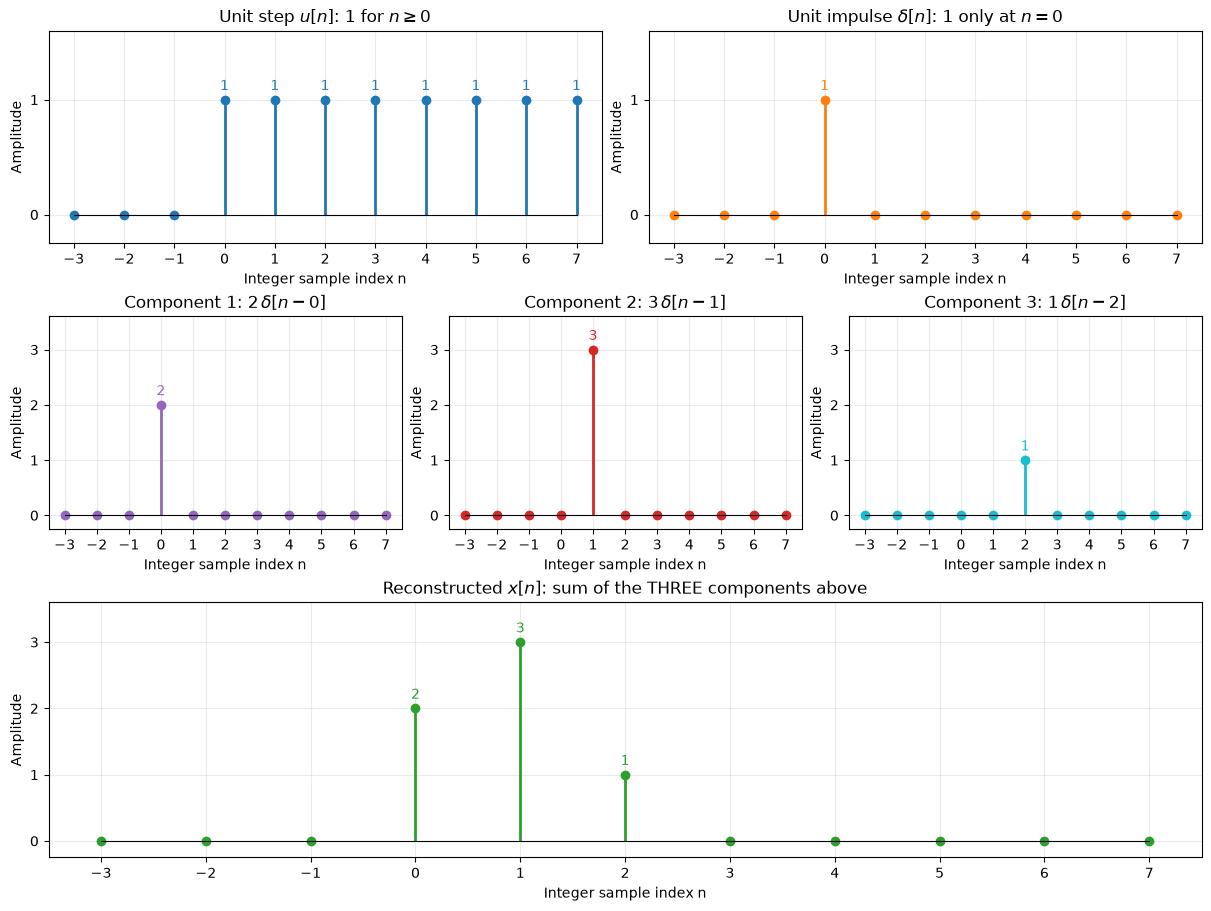

重建信号： {0: 2.0, 1: 3.0, 2: 1.0}
所有未标出非零幅值的整数采样点，其值均为 0；阶跃图只显示有限范围。


In [2]:
n = np.arange(-3, 8)
u = (n >= 0).astype(float)
delta = (n == 0).astype(float)
assert np.array_equal(u - (n >= 1), delta)
x = np.array([2., 3., 1.])  # 对应 n=0、1、2 的幅值，可修改
parts = np.array([v * (n == k) for k, v in enumerate(x)])
reconstructed = parts.sum(axis=0)
assert np.array_equal(reconstructed[(n >= 0) & (n < len(x))], x)

fig = plt.figure(figsize=(12, 9), layout='constrained')
grid = fig.add_gridspec(3, 6, height_ratios=[1, 1, 1.2])

def discrete_plot(ax, values, title, color, upper):
    markers, stems, baseline = ax.stem(n, values, basefmt='k-')
    plt.setp(markers, color=color, markersize=6)
    plt.setp(stems, color=color, linewidth=2)
    plt.setp(baseline, linewidth=0.8)
    ax.set(title=title, xlabel='Integer sample index n', ylabel='Amplitude',
           xlim=(n[0] - 0.5, n[-1] + 0.5), ylim=(-0.25, upper))
    ax.set_xticks(n)
    ax.set_yticks(np.arange(0, upper, 1))
    ax.grid(True, alpha=0.25)
    ax.set_axisbelow(True)
    for ni, value in zip(n, values):
        if value != 0:
            ax.annotate(f'{value:g}', (ni, value), xytext=(0, 7),
                        textcoords='offset points', ha='center', color=color)

upper = max(3.6, float(np.max(x)) + 0.6)
discrete_plot(fig.add_subplot(grid[0, :3]), u,
              r'Unit step $u[n]$: 1 for $n\geq 0$', 'tab:blue', 1.6)
discrete_plot(fig.add_subplot(grid[0, 3:]), delta,
              r'Unit impulse $\delta[n]$: 1 only at $n=0$', 'tab:orange', 1.6)
for k, values in enumerate(parts):
    discrete_plot(fig.add_subplot(grid[1, 2*k:2*k+2]), values,
                  rf'Component {k+1}: ${x[k]:g}\,\delta[n-{k}]$',
                  ['tab:purple', 'tab:red', 'tab:cyan'][k], upper)
discrete_plot(fig.add_subplot(grid[2, :]), reconstructed,
              r'Reconstructed $x[n]$: sum of the THREE components above',
              'tab:green', upper)
plt.show()
print('重建信号：', {int(ni): float(yi) for ni, yi in zip(n, reconstructed) if yi != 0})
print('所有未标出非零幅值的整数采样点，其值均为 0；阶跃图只显示有限范围。')

**观察与应用：** 第二行三个图分别只在 $n=0,1,2$ 处有非零样本，高度为 2、3、1。逐个整数位置相加，即得到最后一行；例如 $x[1]=0+3+0=3$。圆点落在横轴上表示该样本为零，圆点之间没有定义本实验的离散信号值。

单个冲激像一次敲击，复杂输入是多次敲击的加权叠加。修改 `x` 中三个幅值，先预测最后一幅图，再运行验证。之后若知道系统对单位冲激的响应 $h[n]$，就能把这三个输入分别产生的响应相加，计算总输出。

## 实验 2：线性、时不变与响应叠加

**要理解什么：** 理解线性与时不变性怎样把“输入分解”变成“输出响应相加”。

**要验证的数学形式（对照[原笔记](../../../卷积.md)）：**

$$
\begin{gathered}
\boxed{x[k]\delta[n-k]\xrightarrow{T}x[k]h[n-k]} \\[6pt]
 x[n]=\delta[n]+\delta[n-1]\ \Longrightarrow\ \boxed{y[n]=h[n]+h[n-1]}
\end{gathered}
$$

**符号与代码怎样对应：** `h` 是单位冲激响应的前 14 项；`parts[0]` 是第一份响应，`parts[1]` 是向右延迟一格的第二份响应。`np.convolve(x,h)` 独立计算总输出，再与分量和比较。系统按初始静止的 LTI 模型处理。

**怎样读图、怎样判断结果：** 每行左边是输入，右边是其响应。最后一幅按相同 n 把两份响应相加；应有 $y[0]=1$、$y[1]=1.5$、$y[2]=0.75$。`assert` 检查两种计算一致。

**先预测，再改参数：** 把第二个输入幅值改成 2，第二份响应应整体变为两倍，总输出为 h[n]+2h[n-1]。

**本例设置与适用范围：**

覆盖笔记四、五、七。$T\{x[k]\delta[n-k]\}=x[k]h[n-k]$。复现笔记的两个单位冲激。

图按“第一份输入 → 第一份响应；第二份输入 → 第二份响应；总响应”排列。前两份响应在每个整数位置相加得到最后一幅图；例如 $y[1]=0.5+1=1.5$。

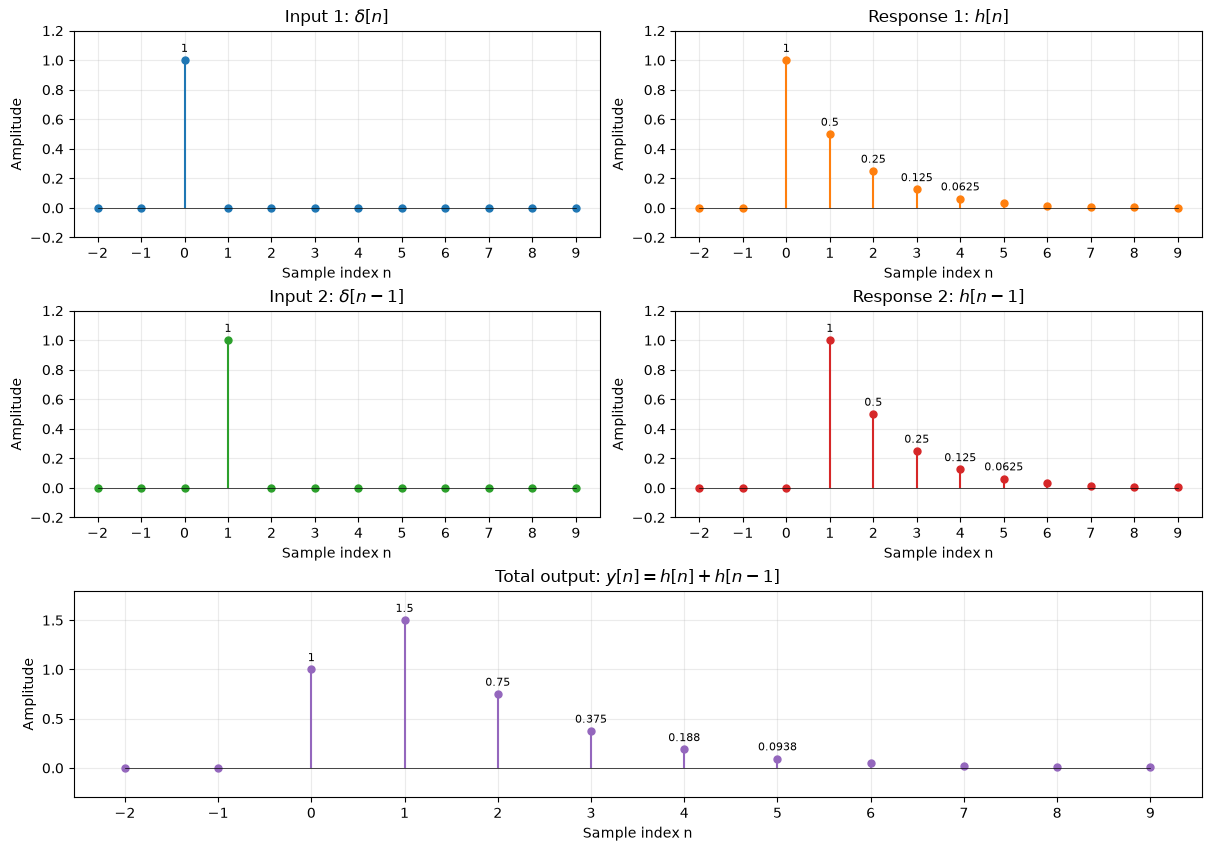

前四项： [1.    1.5   0.75  0.375]
图只显示 n=-2 至 9；计算保留完整的有限卷积结果。


In [3]:
# 两个输入冲激分别产生一份响应；h 仅保留前 14 项用于计算。
h=0.5**np.arange(14)
x=np.array([1.,1.])
parts=np.zeros((len(x),len(x)+len(h)-1))
for k,v in enumerate(x):
    parts[k,k:k+len(h)]=v*h
y=np.convolve(x,h)
assert np.allclose(y,parts.sum(axis=0))
n=np.arange(-2,10)
input0=(n==0).astype(float); input1=(n==1).astype(float)
def at_indices(v):
    result=np.zeros(len(n)); valid=(n>=0)&(n<len(v))
    result[valid]=v[n[valid]]
    return result
# 同一行对照一次输入与它产生的响应；最后一行展示两份响应相加。
graph(n, {
    r'Input 1: $\delta[n]$':input0,
    r'Response 1: $h[n]$':at_indices(parts[0]),
    r'Input 2: $\delta[n-1]$':input1,
    r'Response 2: $h[n-1]$':at_indices(parts[1]),
    r'Total output: $y[n]=h[n]+h[n-1]$':at_indices(y)}, kind='discrete')
print('前四项：',y[:4])
print('图只显示 n=-2 至 9；计算保留完整的有限卷积结果。')

**观察与应用：** 结果应为 1、1.5、0.75、0.375。第二次输入叠加在第一次的余波上，可用于预测连续敲击、回声或药量累积的线性近似。改变衰减系数，观察记忆时长。

## 实验 3：翻转、平移、相乘、求和与因果性

**要理解什么：** 理解卷积求和中的 n、k 和 n−k：固定当前输出时刻，逐个计算各次输入还贡献多少。

**要验证的数学形式（对照[原笔记](../../../卷积.md)）：**

$$
\begin{gathered}
\boxed{y[n]=\sum_{k=-\infty}^{+\infty}x[k]h[n-k]} \\[6pt]
 h[m]=0\ (m<0)\ \Longrightarrow\ \boxed{y[n]=\sum_{k=-\infty}^{n}x[k]h[n-k]}
\end{gathered}
$$

**符号与代码怎样对应：** `n` 每次固定为 0、1、2 或 3；一组三图的横轴都是求和变量 `k`，并非输出时刻。`idx=n-k` 表示第 k 次输入到当前经过多久；`hk` 是 h[n-k]，数组范围外为零，`x*hk` 是逐项贡献。此例明确把 h 定为长度 4 的有限序列。

**怎样读图、怎样判断结果：** 例如固定 $n=2$：$y[2]=2\times0.25+3\times0.5+1\times1=3$。三幅图依次读作“输入大小”“剩余响应”“两者乘积”；最后一幅各竖杆高度的和就是一个输出值。n=0、1、2、3 的输出应分别为 2、4、3、1.5。

**先预测，再改参数：** 先手算 y[3]，再看图；把 h[1] 从 0.5 改成 0.8，找出哪些贡献项受影响。

**本例设置与适用范围：**

覆盖笔记六。固定 $n$ 后沿 $k$ 画出 $x[k]h[n-k]$。数组索引越界处按零处理，绝不循环回绕。

固定 n=0：各项贡献 [2. 0. 0.]，相加=2，直接卷积参考=2


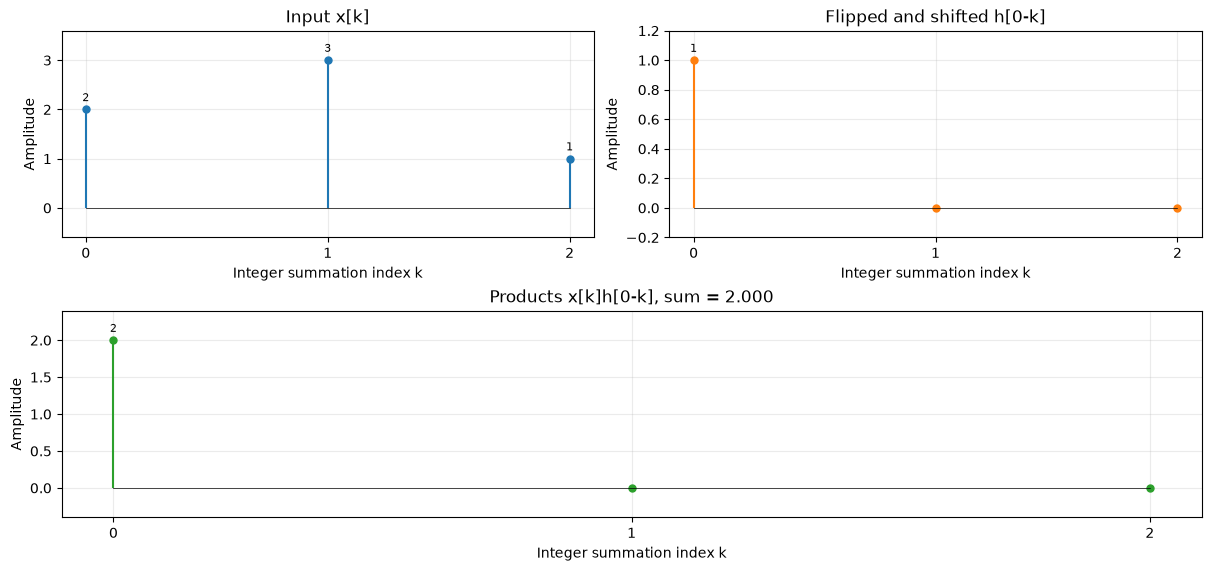

固定 n=1：各项贡献 [1. 3. 0.]，相加=4，直接卷积参考=4


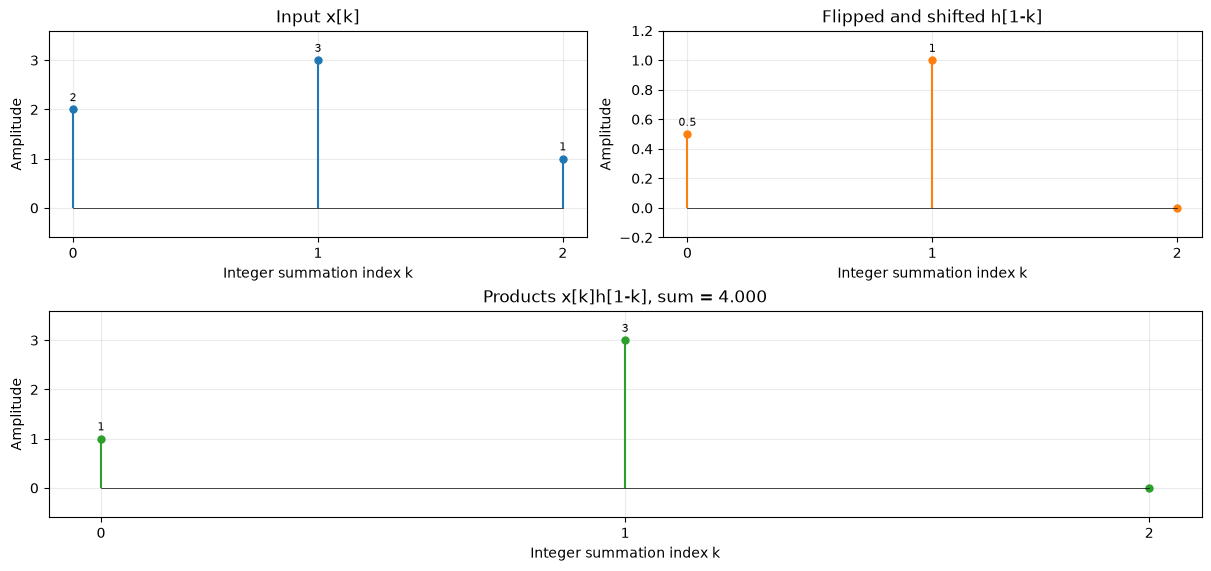

固定 n=2：各项贡献 [0.5 1.5 1. ]，相加=3，直接卷积参考=3


固定 **n=2**，逐项对应卷积公式：

|输入时刻 k|输入 x[k]|经过时间 n-k|剩余响应 h[n-k]|乘积贡献|
|---:|---:|---:|---:|---:|
|0|2|2|0.25|0.5|
|1|3|1|0.5|1.5|
|2|1|0|1|1|

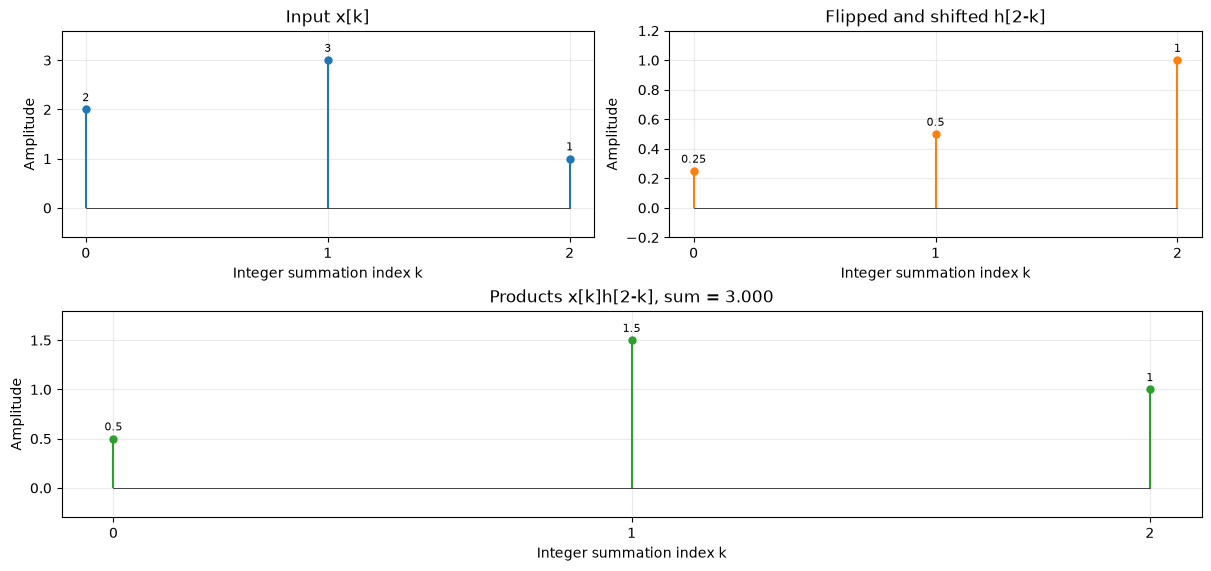

固定 n=3：各项贡献 [0.25 0.75 0.5 ]，相加=1.5，直接卷积参考=1.5


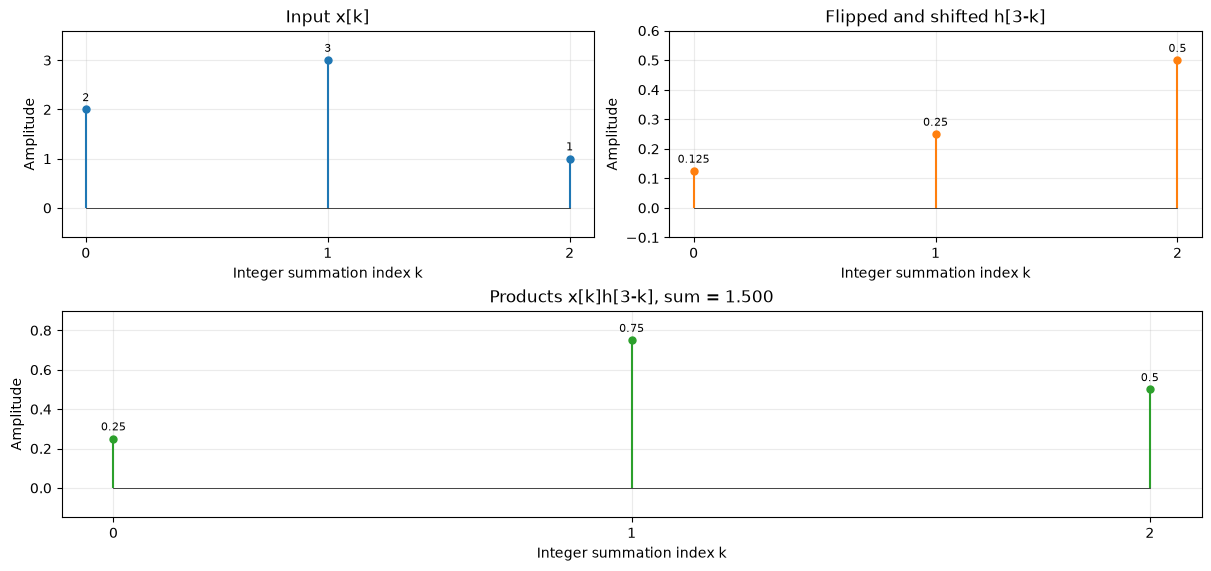

完整卷积： [2.    4.    3.    1.5   0.625 0.125]


In [4]:
x=np.array([2.,3.,1.]); h=np.array([1.,0.5,0.25,0.125]); k=np.arange(len(x))
for n in [0,1,2,3]:
    idx=n-k
    hk=np.zeros(len(k)); valid=(idx>=0)&(idx<len(h))
    hk[valid]=h[idx[valid]]
    contribution=x*hk
    expected=np.convolve(x,h)[n]
    assert np.isclose(np.sum(contribution),expected)
    print(f'固定 n={n}：各项贡献 {contribution}，相加={contribution.sum():g}，直接卷积参考={expected:g}')
    if n==2:
        rows=['|输入时刻 k|输入 x[k]|经过时间 n-k|剩余响应 h[n-k]|乘积贡献|',
              '|---:|---:|---:|---:|---:|']
        for ki,xi,hi,ci in zip(k,x,hk,contribution):
            rows.append(f'|{ki}|{xi:g}|{n-ki}|{hi:g}|{ci:g}|')
        display(Markdown('固定 **n=2**，逐项对应卷积公式：\n\n'+'\n'.join(rows)))
    graph(k,{'Input x[k]':x,f'Flipped and shifted h[{n}-k]':hk,
             f'Products x[k]h[{n}-k], sum = {np.sum(x*hk):.3f}':x*hk},
          xlabel='Integer summation index k',kind='discrete')
print('完整卷积：',np.convolve(x,h))

**观察与应用：** n−k 是输入发生后经过的时间。因果 h 的负索引为零，所以未来输入无贡献。这一图能帮助排查数字滤波程序的偏移错误。

## 实验 4：连续冲激的单位面积近似与筛选

**要理解什么：** 理解连续冲激的“1”是积分面积；用窄脉冲观察筛选性质与阶跃。

**要验证的数学形式（对照[原笔记](../../../卷积.md)）：**

$$
\begin{gathered}
\boxed{\int_{-\infty}^{+\infty}\delta(t)\,dt=1} \\[6pt]
\boxed{\int_{-\infty}^{+\infty}f(t)\delta(t)\,dt=f(0)} \\[6pt]
 u(t)=\int_{-\infty}^{t}\delta(\tau)\,d\tau
\end{gathered}
$$

**符号与代码怎样对应：** `d` 是用采样网格近似的单位面积矩形脉冲；`eps` 是宽度，`f=cos(t)+t`。`sum(f*d)*dt` 对应筛选积分，累计梯形积分对应阶跃；真实 δ 是分布，图中的有限矩形只是近似。

**怎样读图、怎样判断结果：** 每种宽度的面积应为 1；筛选结果随宽度变窄接近 f(0)=1；累计积分曲线的过渡区逐渐变窄。这里观察的是极限趋势。

**先预测，再改参数：** 把 f 改为 cos(t)+2，预测筛选结果应趋近 3；继续减小宽度时也要保证足够多采样点。

**本例设置与适用范围：**

覆盖笔记二、八。连续冲激是分布；用宽度 $\epsilon$、高度 $1/\epsilon$ 的矩形近似，比较积分而不是峰高。

宽度=0.8, 面积=1.000000, 筛选=0.973539, f(0)=1
宽度=0.2, 面积=1.000000, 筛选=0.998284, f(0)=1
宽度=0.05, 面积=1.000000, 筛选=0.999895, f(0)=1


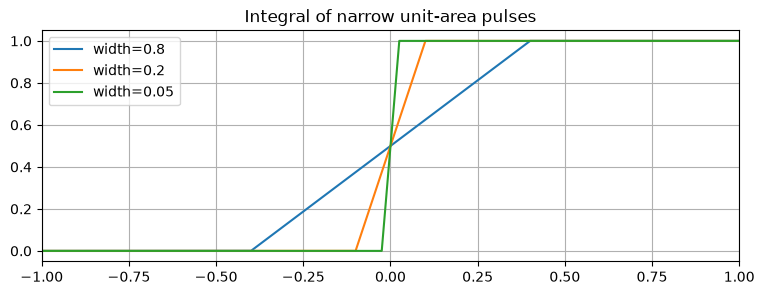

In [5]:
t=np.linspace(-2,2,40001); dt=t[1]-t[0]; f=np.cos(t)+t
fig,ax=plt.subplots()
for eps in [0.8,0.2,0.05]:
    d=(np.abs(t)<eps/2).astype(float)
    d/=np.sum(d)*dt
    print(f'宽度={eps}, 面积={np.sum(d)*dt:.6f}, 筛选={np.sum(f*d)*dt:.6f}, f(0)=1')
    ax.plot(t,integrate.cumulative_trapezoid(d,t,initial=0),label=f'width={eps}')
ax.set(xlim=(-1,1),title='Integral of narrow unit-area pulses'); ax.legend(); plt.show()

**观察与应用：** 脉冲越窄，筛选积分越接近 f(0)，积分曲线越接近阶跃。用于理解短脉冲测量；固定面积时高度必须增加，不能把连续冲激简单设为某一个采样点的 1。

## 实验 5：连续卷积与采样步长

**要理解什么：** 理解连续卷积中的积分权重，以及数值求和为什么必须乘采样步长。

**要验证的数学形式（对照[原笔记](../../../卷积.md)）：**

$$
\begin{gathered}
\boxed{y(t)=\int_{-\infty}^{+\infty}x(\tau)h(t-\tau)\,d\tau} \\[6pt]
 x(t)=u(t),\ h(t)=e^{-t}u(t)\ \Longrightarrow\ y(t)=(1-e^{-t})u(t)
\end{gathered}
$$

**符号与代码怎样对应：** `np.ones_like(t)` 是 t≥0 范围的阶跃输入，`exp(-t)` 是冲激响应；`np.convolve(...)*dt` 用矩形求和近似积分。解析参考 `exact` 来自 ∫₀ᵗ exp(−(t−τ))dτ。

**怎样读图、怎样判断结果：** 先区分输入图、h 图与输出图；输出从 0 趋向 1。打印的最大误差应随 dt 减小而下降；数值 y[0] 的小误差来自端点的矩形求和，不表示理论响应瞬间跳到 dt。

**先预测，再改参数：** 暂时去掉乘 dt，观察振幅怎样随采样率失真，再恢复。

**本例设置与适用范围：**

覆盖笔记八。$e^{-t}u(t)*u(t)=(1-e^{-t})u(t)$。黎曼和必须乘 $\Delta t$。

dt=0.05: 最大误差=0.05000
dt=0.01: 最大误差=0.01000
dt=0.002: 最大误差=0.00200


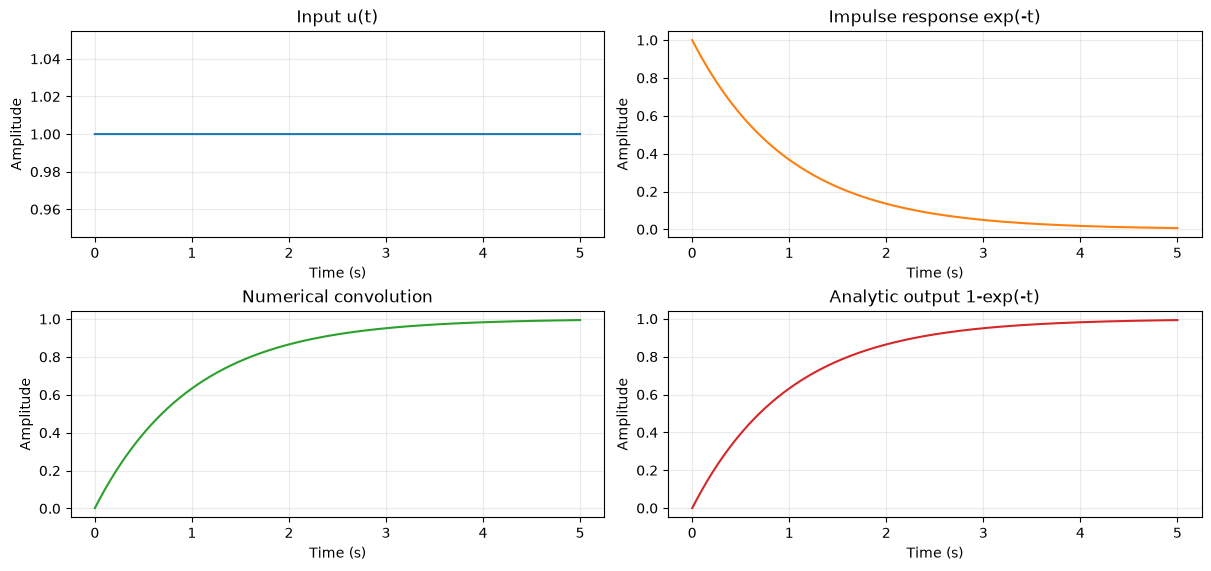

[<Axes: title={'center': 'Input u(t)'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'Impulse response exp(-t)'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'Numerical convolution'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'Analytic output 1-exp(-t)'}, xlabel='Time (s)', ylabel='Amplitude'>]

In [6]:
for dt in [0.05,0.01,0.002]:
    t=np.arange(0,5+dt/2,dt)
    y=np.convolve(np.ones_like(t),np.exp(-t))[:len(t)]*dt
    exact=1-np.exp(-t)
    print(f'dt={dt}: 最大误差={err(y,exact):.5f}')
graph(t,{'Input u(t)':np.ones_like(t),'Impulse response exp(-t)':np.exp(-t),
         'Numerical convolution':y,'Analytic output 1-exp(-t)':exact},'Time (s)',kind='continuous')

**观察与应用：** 减小步长后误差下降；初始点的矩形积分误差也会缩小。这对应 RC 电路充电或一阶温度响应，遗漏 dt 会使结果随采样率变化。

## 实验 6：卷积的交换、结合与分配律

**要理解什么：** 理解卷积三条代数性质为何允许调整 LTI 模块的连接方式。

**要验证的数学形式（对照[原笔记](../../../卷积.md)）：**

$$
\begin{gathered}
\boxed{x*h=h*x} \\[6pt]
\boxed{(x*h_1)*h_2=x*(h_1*h_2)} \\[6pt]
\boxed{x*(h_1+h_2)=x*h_1+x*h_2}
\end{gathered}
$$

**符号与代码怎样对应：** `a,b` 对比交换律；`c,d` 对比结合律；`e,f` 对比分配律。所有数组从 n=0 编号并在范围外为零，计算保留完整卷积尾部；图的两条支路分别是 x*h1 与 x*h2。

**怎样读图、怎样判断结果：** 三个误差应只有浮点舍入量级，`assert` 要求小于 1e−12。分量图逐点相加后，应与等效系统图对应位置一致。

**先预测，再改参数：** 修改 h1、h2 的系数再验证；若两者长度不同，先补零对齐才能在代码中相加。

**本例设置与适用范围：**

覆盖笔记八。用有限序列进行完整卷积，验证三条代数性质。

交换、结合、分配误差： 0.0 2.220446049250313e-16 2.220446049250313e-16


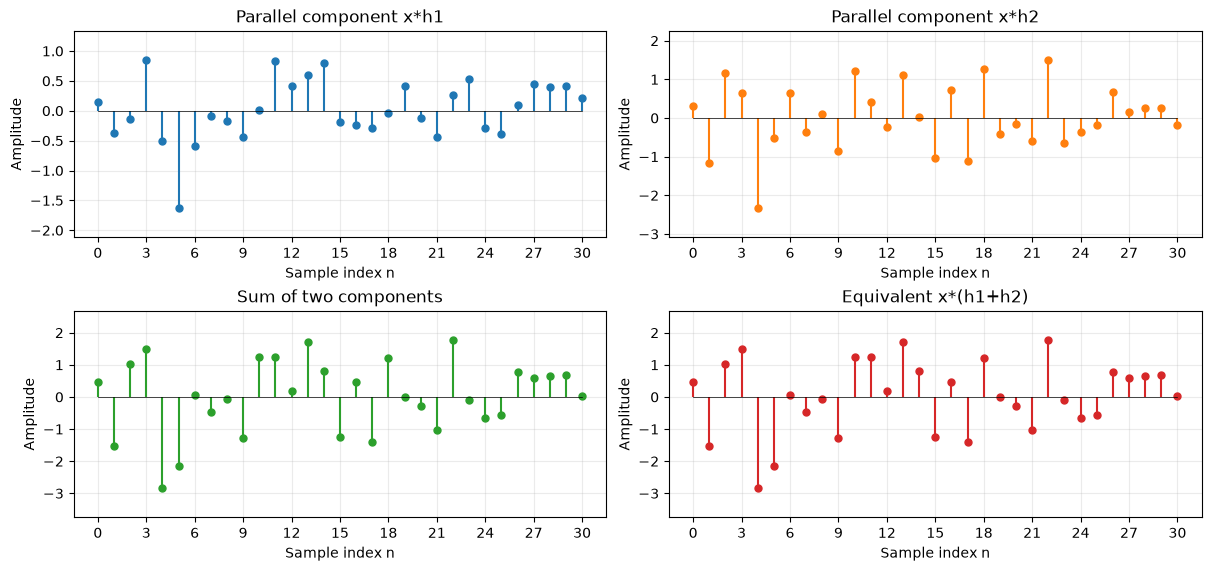

[<Axes: title={'center': 'Parallel component x*h1'}, xlabel='Sample index n', ylabel='Amplitude'>,
 <Axes: title={'center': 'Parallel component x*h2'}, xlabel='Sample index n', ylabel='Amplitude'>,
 <Axes: title={'center': 'Sum of two components'}, xlabel='Sample index n', ylabel='Amplitude'>,
 <Axes: title={'center': 'Equivalent x*(h1+h2)'}, xlabel='Sample index n', ylabel='Amplitude'>]

In [7]:
x=rng.normal(size=30); h1=np.array([0.5,0.5]); h2=np.array([1.,-0.4])
a=np.convolve(x,h1); b=np.convolve(h1,x)
c=np.convolve(a,h2); d=np.convolve(x,np.convolve(h1,h2))
e=np.convolve(x,h1+h2); f=np.convolve(x,h1)+np.convolve(x,h2)
print('交换、结合、分配误差：',err(a,b),err(c,d),err(e,f))
assert max(err(a,b),err(c,d),err(e,f))<1e-12
graph(np.arange(len(e)),{'Parallel component x*h1':np.convolve(x,h1),
    'Parallel component x*h2':np.convolve(x,h2),'Sum of two components':f,
    'Equivalent x*(h1+h2)':e},kind='discrete')

**观察与应用：** 可把多个 LTI 模块合成为一个滤波器，减少重复计算。这里保留完整尾部；中途截断会破坏这种比较。

## 实验 7：实际例子：回声与测量平滑

**要理解什么：** 用回声与降噪理解：卷积会把现在与过去的输入加权叠加，平滑会付出延迟。

**要验证的数学形式（对照[原笔记](../../../卷积.md)）：**

$$
\begin{gathered}
\boxed{y[n]=\sum_kx[k]h[n-k]} \\[6pt]
 h_e[n]=\delta[n]+0.6\delta[n-d]\Rightarrow y_e[n]=x[n]+0.6x[n-d] \\[6pt]
 h_M[n]=\begin{cases}1/M,&0\le n<M\\0,&\text{其他}\end{cases}
\end{gathered}
$$

**符号与代码怎样对应：** 回声支路的 `echo_part` 是 0.6 倍延迟输入；`echo` 是它与 `clean` 的和。另一路 `noisy=clean+noise`，`smooth` 用长度 M 的因果移动平均处理。回声支路与平滑支路是两个用途，别把全部子图相加。

**怎样读图、怎样判断结果：** 回声图应满足原信号+延迟分量=回声输出；平滑图高频抖动减弱但峰的位置滞后。RMSE 分别在补偿延迟前后计算，不能只看未对齐的波形差就判断降噪失败。

**先预测，再改参数：** 把 d 改大观察回声推迟；把 M 改为另一个奇数，预测平滑与延迟的变化。

**本例设置与适用范围：**

回声 $h[n]=\delta[n]+0.6\delta[n-d]$；因果移动平均 $h[n]=1/M,\ 0\le n<M$。

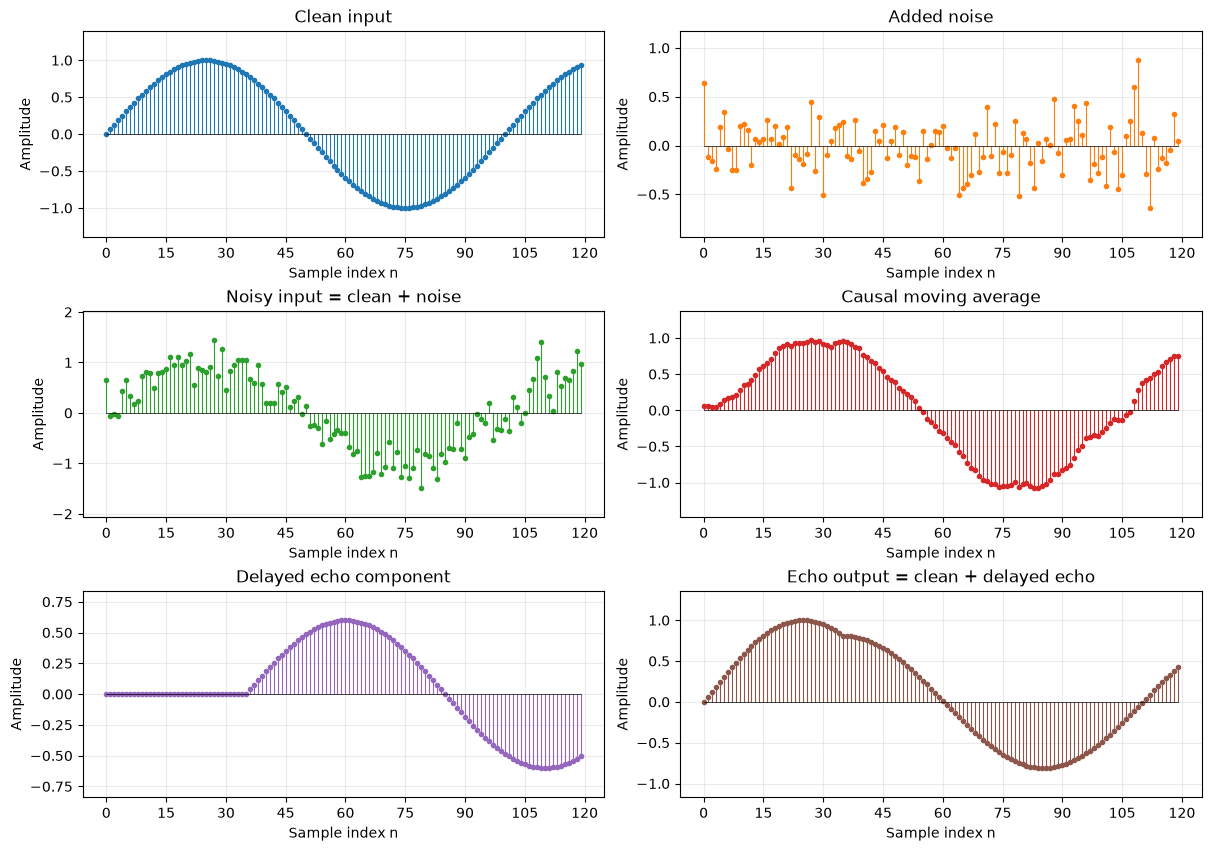

含延迟的 RMSE： 0.23564244987955618
补偿延迟后 RMSE： 0.08317374944048364


In [8]:
N=400; n=np.arange(N); clean=np.sin(2*np.pi*n/100)
noise=0.3*rng.normal(size=N); noisy=clean+noise; M=11; delay=35
smooth=signal.lfilter(np.ones(M)/M,[1],noisy)
echo_h=np.zeros(delay+1); echo_h[0]=1; echo_h[-1]=0.6
echo=np.convolve(clean,echo_h)[:N]
echo_part=np.r_[np.zeros(delay),0.6*clean[:-delay]]
assert np.allclose(echo,clean+echo_part)
view=slice(0,120)
graph(n[view],{'Clean input':clean[view],'Added noise':noise[view],
    'Noisy input = clean + noise':noisy[view],'Causal moving average':smooth[view],
    'Delayed echo component':echo_part[view],'Echo output = clean + delayed echo':echo[view]},kind='discrete')
lag=(M-1)//2
print('含延迟的 RMSE：',np.sqrt(np.mean((smooth[M:]-clean[M:])**2)))
print('补偿延迟后 RMSE：',np.sqrt(np.mean((smooth[M:]-clean[M-lag:N-lag])**2)))

**观察与应用：** 增大 M 能抑制噪声，也会增加延迟、抹平快速变化。适合温度与流量显示；若用于报警，必须权衡降噪与响应速度。回声的 delay 控制重复声到达时间。

## 实验记录

每次选一个参数，记录：原值、新值、图像变化、指标变化、可以解决的实际问题、模型的适用条件。先预测结果，再运行验证。